IA Explicable (XAI) - SHAP Values
Ejemplo: ¿qué variables influyen más en el PRECIO de una casa?

Dataset público: California Housing (incluido en scikit-learn). Cada fila es un grupo de casas (bloque censal) en California. Objetivo: predecir el valor medio de las casas (en cientos de miles de USD).

In [14]:
# 1. Librerías
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
import pandas as pd
import shap

In [15]:
# 2. Cargar dataset
data = fetch_california_housing()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

In [16]:
X.isna().sum()
X.shape

(20640, 8)

In [17]:
# 3. Separar entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [18]:
# 4. Entrenar XGBoost
model = XGBRegressor(n_estimators=100,random_state=42,enable_categorical=False)
model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=None, num_parallel_tree=None, ...)

In [19]:
model.score(X_test, y_test)

0.8366589575055071

Crear un objeto explicador (shap.Explainer), el cual se utiliza en IA Explicable (XAI) para calcular la importancia de las características (features).

**shap.Explainer(model, X_train)**. # **model** es el modelo ya entrenado a ser evaluado por SHAP.

In [20]:
# 5. Crear explicador SHAP
explainer = shap.Explainer(model, X_train)
#explainer = shap.TreeExplainer(model,feature_perturbation="tree_path_dependent")

In [21]:
# 6. Calcular SHAP values
# Calcula la contribución individual de cada variable X_i Para cada casa (fila) en X_test.
shap_values = explainer(X_test)

 99%|===================| 4093/4128 [00:32<00:00]       

# **Importancia Global**

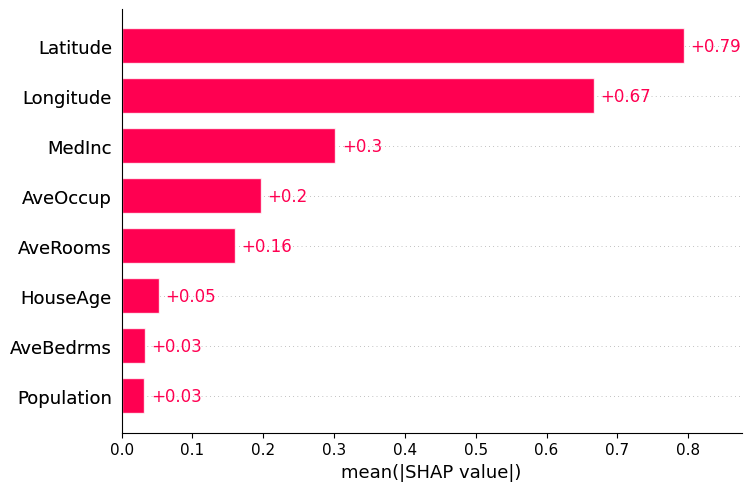

In [22]:
shap.plots.bar(shap_values)

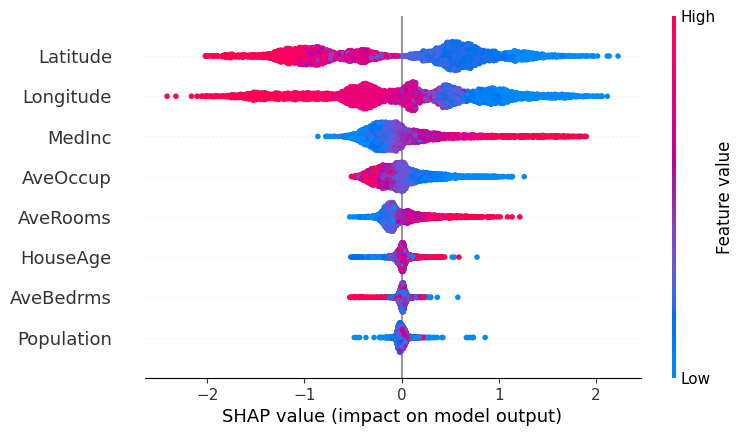

In [23]:
# 8. Summary Plot
#Gráfico de "enjambre" (beeswarm plot).
#Muestra la importancia de la variable, la dirección de su efecto y el valor real de los datos.
shap.plots.beeswarm(shap_values)

# **Importancia Local**

In [24]:
# 1. Crear una casa nueva
new_house = pd.DataFrame({
    "MedInc": [5.0],
    "HouseAge": [20.0],
    "AveRooms": [6.0],
    "AveBedrms": [2.0],
    "Population": [1500.0],
    "AveOccup": [3.0],
    "Latitude": [34.0],
    "Longitude": [-118.0]
})

In [25]:
# 2. Realizar la predicción
prediction = model.predict(new_house)
print("Predicción:", prediction)

Predicción: [2.1953208]


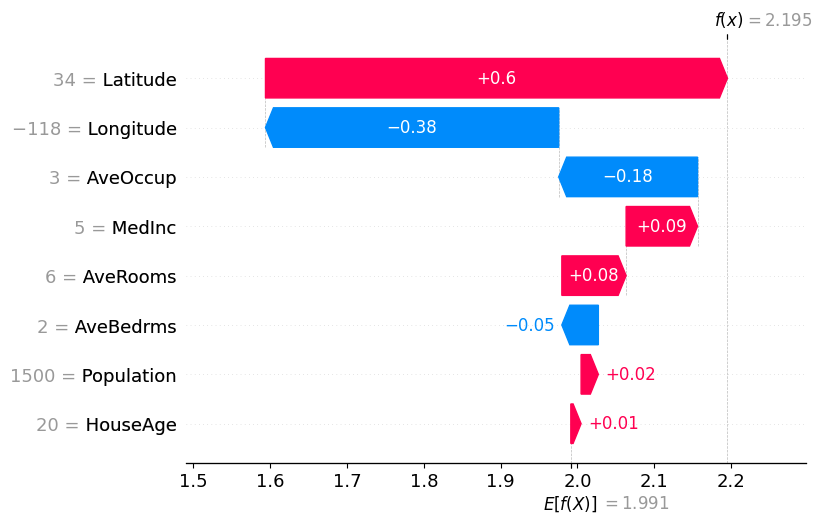

In [26]:
# 3. Calcular SHAP values para la nueva casa
new_house_shap = explainer(new_house)

# 4. Mostrar explicación local
shap.plots.waterfall(new_house_shap[0])